# Customer Churn & CLV — Exploratory Data Analysis

## Objective

The objective of this notebook is to understand how customers buy before defining what "churn" means.

The analysis focuses on four questions that will directly affect how the model is built:

1. Is there seasonality in the sales?
2. How many orders does a typical customer place?
3. How much time passes between two orders of the same customer?
4. Is the revenue concentrated in a few customers?

In [1]:
# Import all the libraries necessary for this section
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the clean sales data
DATA_PATH = Path("../data/processed/sales_clean.csv")

sales_df = pd.read_csv(DATA_PATH, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})

sales_df.shape

(776579, 9)

In [3]:
sales_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## 1) Seasonality: How do sales evolve over time?

In [4]:
# Calculate the monthly revenue and the number of active customers per month
monthly = (
    sales_df
    .set_index("InvoiceDate")
    .resample("MS")
    .agg(revenue=("Revenue", "sum"), customers=("CustomerID", "nunique"))
    .reset_index()
)

# Remove December 2011 because it only has 9 days
monthly = monthly.iloc[:-1]

monthly.head()

,InvoiceDate,revenue,customers
0,2009-12-01,677916.07,951
1,2010-01-01,533712.98,701
2,2010-02-01,497937.57,771
3,2010-03-01,665973.67,1051
4,2010-04-01,585127.43,939


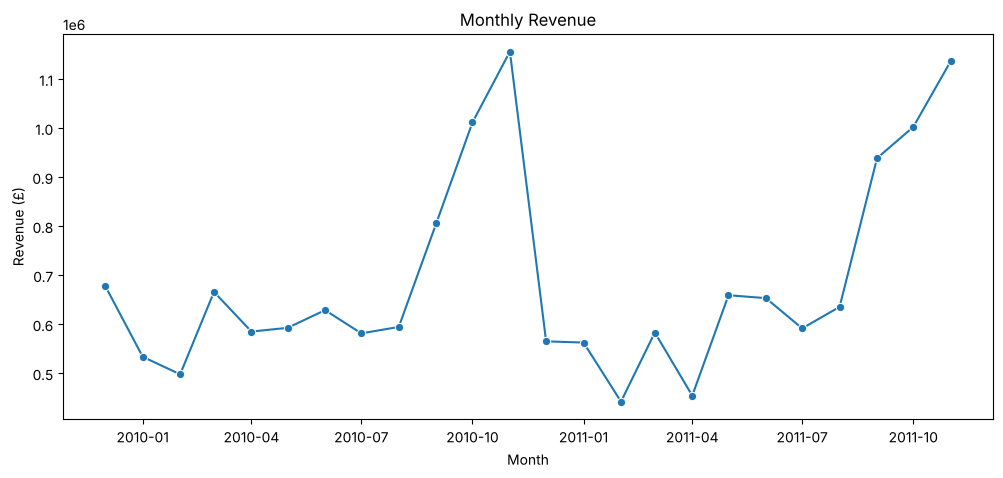

In [5]:
# Plot the monthly revenue
plt.figure(figsize=(12, 5))

sns.lineplot(data=monthly, x="InvoiceDate", y="revenue", marker="o")

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.show()

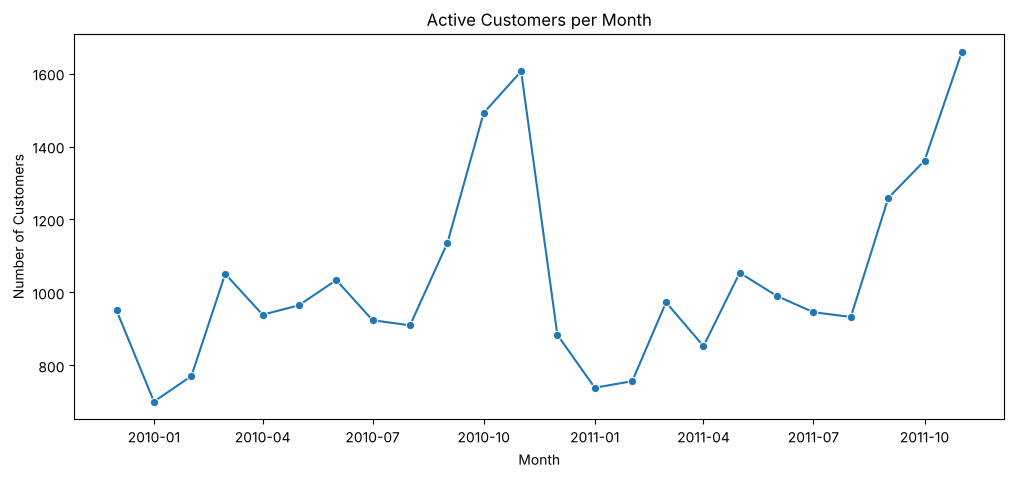

In [6]:
# Plot the number of active customers per month
plt.figure(figsize=(12, 5))

sns.lineplot(data=monthly, x="InvoiceDate", y="customers", marker="o")

plt.title("Active Customers per Month")
plt.xlabel("Month")
plt.ylabel("Number of Customers")
plt.show()

### Key Findings

- There is a **strong seasonality**: revenue and active customers increase a lot between September and November, in both years.
- This makes sense for a gift retailer whose customers are mainly shops buying stock before Christmas.
- After Christmas, activity drops.
- **Impact on the project:** the probability of a customer not buying in the next months will depend on the season. I will need a feature for the season and I should test the model on the same season in which it would be used.

## 2) Orders: How many orders does a typical customer place?

In [7]:
# Create a table with one row per order (invoice)
orders_df = (
    sales_df
    .groupby(["CustomerID", "Invoice"])
    .agg(date=("InvoiceDate", "min"), value=("Revenue", "sum"))
    .reset_index()
    .sort_values(["CustomerID", "date"])
)

orders_df.head()

,CustomerID,Invoice,date,value
0,12346,499763,2010-03-02 13:08:00,27.05
1,12346,513774,2010-06-28 13:53:00,142.31
2,12346,541431,2011-01-18 10:01:00,77183.60
3,12347,529924,2010-10-31 14:20:00,611.53
4,12347,537626,2010-12-07 14:57:00,711.79


In [8]:
# Count the number of orders per customer
orders_per_customer = orders_df.groupby("CustomerID").size()

orders_per_customer.describe()

count    5852.000000
mean        6.253247
std        12.749286
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       373.000000
dtype: float64

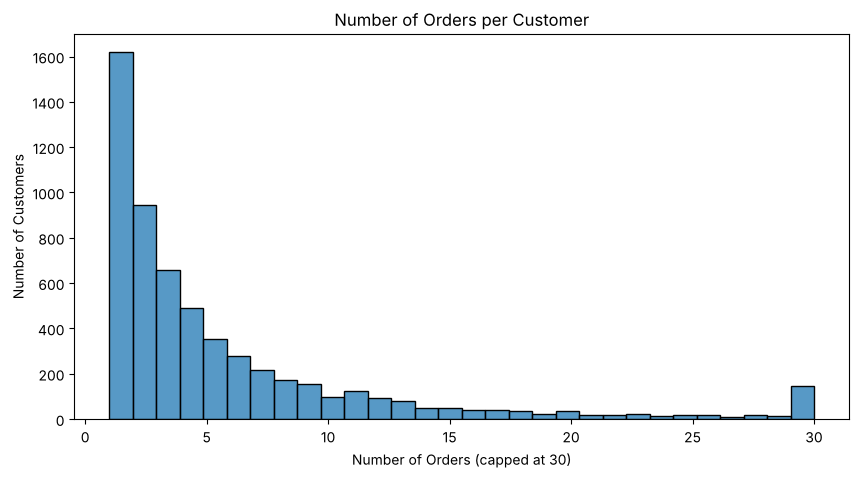

In [9]:
# Plot the distribution of orders per customer (capped at 30 orders to see the shape)
plt.figure(figsize=(10, 5))

sns.histplot(orders_per_customer.clip(upper=30), bins=30)

plt.title("Number of Orders per Customer")
plt.xlabel("Number of Orders (capped at 30)")
plt.ylabel("Number of Customers")
plt.show()

In [10]:
# Check the percentage of customers who only bought once
one_time_buyers = (orders_per_customer == 1).mean() * 100
print(f"One-time buyers: {one_time_buyers:.1f}%")

One-time buyers: 27.6%


### Key Findings

- The distribution is very right-skewed: most customers place only a few orders and a small group places many.
- The median customer has 3 orders.
- **27.6% of the customers only bought once.** They will probably have a high risk of churn, but also a low value.

## 3) Purchase cycle: How many days pass between two orders?

In [11]:
# Calculate the days between consecutive orders of the same customer
orders_df["days_since_previous_order"] = orders_df.groupby("CustomerID")["date"].diff().dt.days

days_between_orders = orders_df["days_since_previous_order"].dropna()

days_between_orders.quantile([0.5, 0.75, 0.8, 0.9])

0.50     25.0
0.75     62.0
0.80     77.0
0.90    135.0
Name: days_since_previous_order, dtype: float64

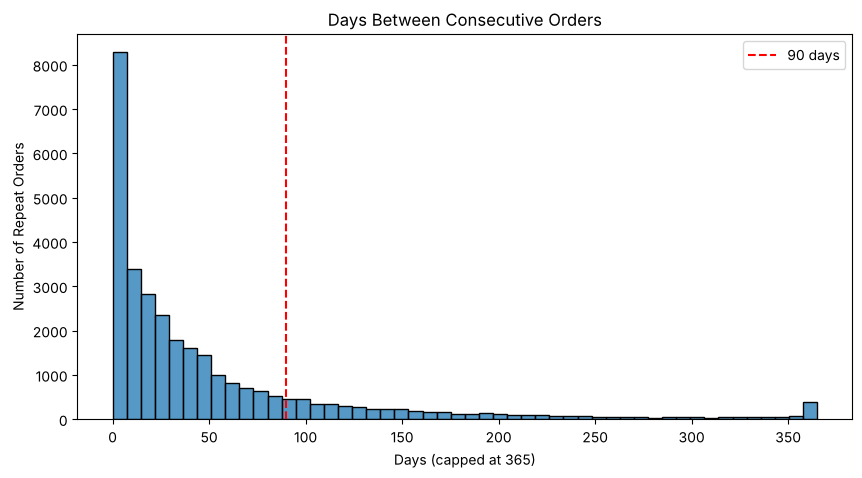

In [12]:
# Plot the distribution of days between orders and mark 90 days
plt.figure(figsize=(10, 5))

sns.histplot(days_between_orders.clip(upper=365), bins=50)
plt.axvline(90, color="red", linestyle="--", label="90 days")

plt.title("Days Between Consecutive Orders")
plt.xlabel("Days (capped at 365)")
plt.ylabel("Number of Repeat Orders")
plt.legend()
plt.show()

### Key Findings

- The median time between two orders is **25 days**.
- **80% of the repeat orders happen within 77 days** of the previous one, and 90% within 135 days.
- So, if a customer doesn't buy for a full quarter (90 days), that is unusual behaviour and not just a normal gap between orders.
- **Impact on the project:** this is the main argument to define churn with a **90-day window**. It also matches how marketing usually plans campaigns (quarterly).

## 4) Value: Is the revenue concentrated in a few customers?

In [13]:
# Calculate the total revenue per customer, sorted from highest to lowest
revenue_per_customer = orders_df.groupby("CustomerID")["value"].sum().sort_values(ascending=False)

# Calculate the cumulative share of revenue
cumulative_share = revenue_per_customer.cumsum() / revenue_per_customer.sum()
customer_share = np.arange(1, len(cumulative_share) + 1) / len(cumulative_share)

top_10_share = cumulative_share.iloc[int(len(cumulative_share) * 0.10)]
print(f"Revenue generated by the top 10% of customers: {top_10_share:.1%}")

Revenue generated by the top 10% of customers: 63.9%


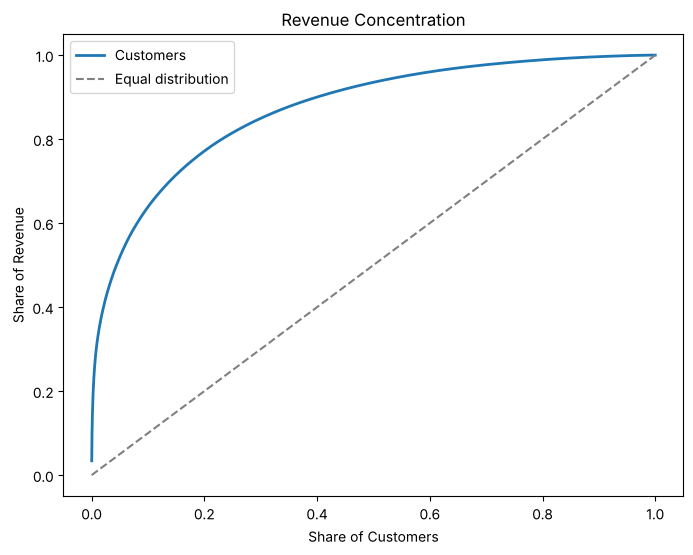

In [14]:
# Plot the revenue concentration curve
plt.figure(figsize=(8, 6))

plt.plot(customer_share, cumulative_share.values, linewidth=2, label="Customers")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Equal distribution")

plt.title("Revenue Concentration")
plt.xlabel("Share of Customers")
plt.ylabel("Share of Revenue")
plt.legend()
plt.show()

### Key Findings

- The revenue is very concentrated: **the top 10% of customers generate 64% of the revenue** (Pareto principle).
- Losing one of these customers costs much more than losing many small ones.
- **Impact on the project:** predicting *who* will leave is not enough. I also need to know *how much* each customer is worth, so the value of the customer will be combined with the churn probability in the business stage.

## 5) Countries: Where are the customers from?

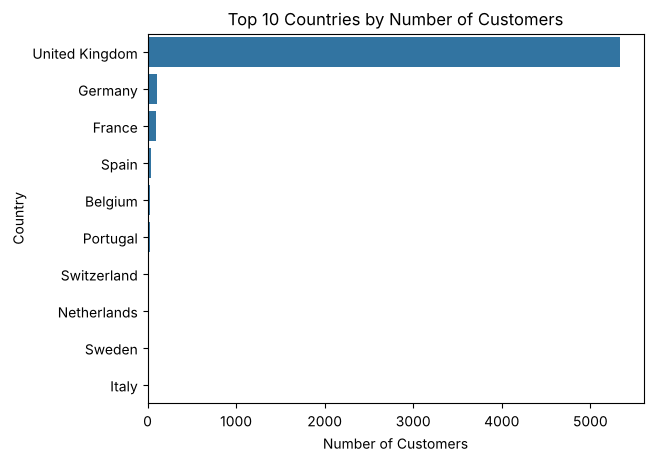

In [15]:
# Count the number of customers per country
customers_per_country = (
    sales_df.groupby("Country")["CustomerID"].nunique().sort_values(ascending=False).head(10)
)

sns.barplot(x=customers_per_country.values, y=customers_per_country.index)

plt.title("Top 10 Countries by Number of Customers")
plt.xlabel("Number of Customers")
plt.ylabel("Country")
plt.show()

### Key Findings

- About 90% of the customers are from the United Kingdom. I will include a simple feature `is_uk` instead of using every country.

## Conclusions

The EDA was used to take three decisions for the next stages:

1. **Churn window of 90 days**, because 80% of repeat purchases happen within 77 days.
2. **Seasonality must be considered**: a feature for the Q4 peak and a test set in the same season (September → December).
3. **Customer value matters**: revenue is very concentrated, so the final recommendation will combine churn probability with customer value.